사용 디바이스: cuda
--- Running Online DPO Pipeline Comparison across Betas (ALIGN_ITERATIONS fixed at 1000) ---
--- Targeting Modes: [6, 7] ---
--- Using KD Sampling Beta = 1.25 ---

################################################################################
### TESTING WITH N_FINAL_MODES = 4 ###
################################################################################

--- Testing BETA_DPO = 0.10 (20 trials) ---
  Trial 1/20 | Pipeline A (KD -> Align)...
    -> Result A: Precision=-0.993, Recall=-11.178, Target Precision=-1.221, Reward=9.646
  Trial 1/20 | Pipeline B (Align -> KD)...
    -> Result B: Precision=-0.933, Recall=-15.520, Target Precision=0.458, Reward=9.996
  Trial 2/20 | Pipeline A (KD -> Align)...
    -> Result A: Precision=-1.047, Recall=-11.008, Target Precision=-1.777, Reward=9.467
  Trial 2/20 | Pipeline B (Align -> KD)...
    -> Result B: Precision=-0.989, Recall=-9.883, Target Precision=0.310, Reward=9.955
  Trial 3/20 | Pipeline A (KD -> Align)...
    -> R

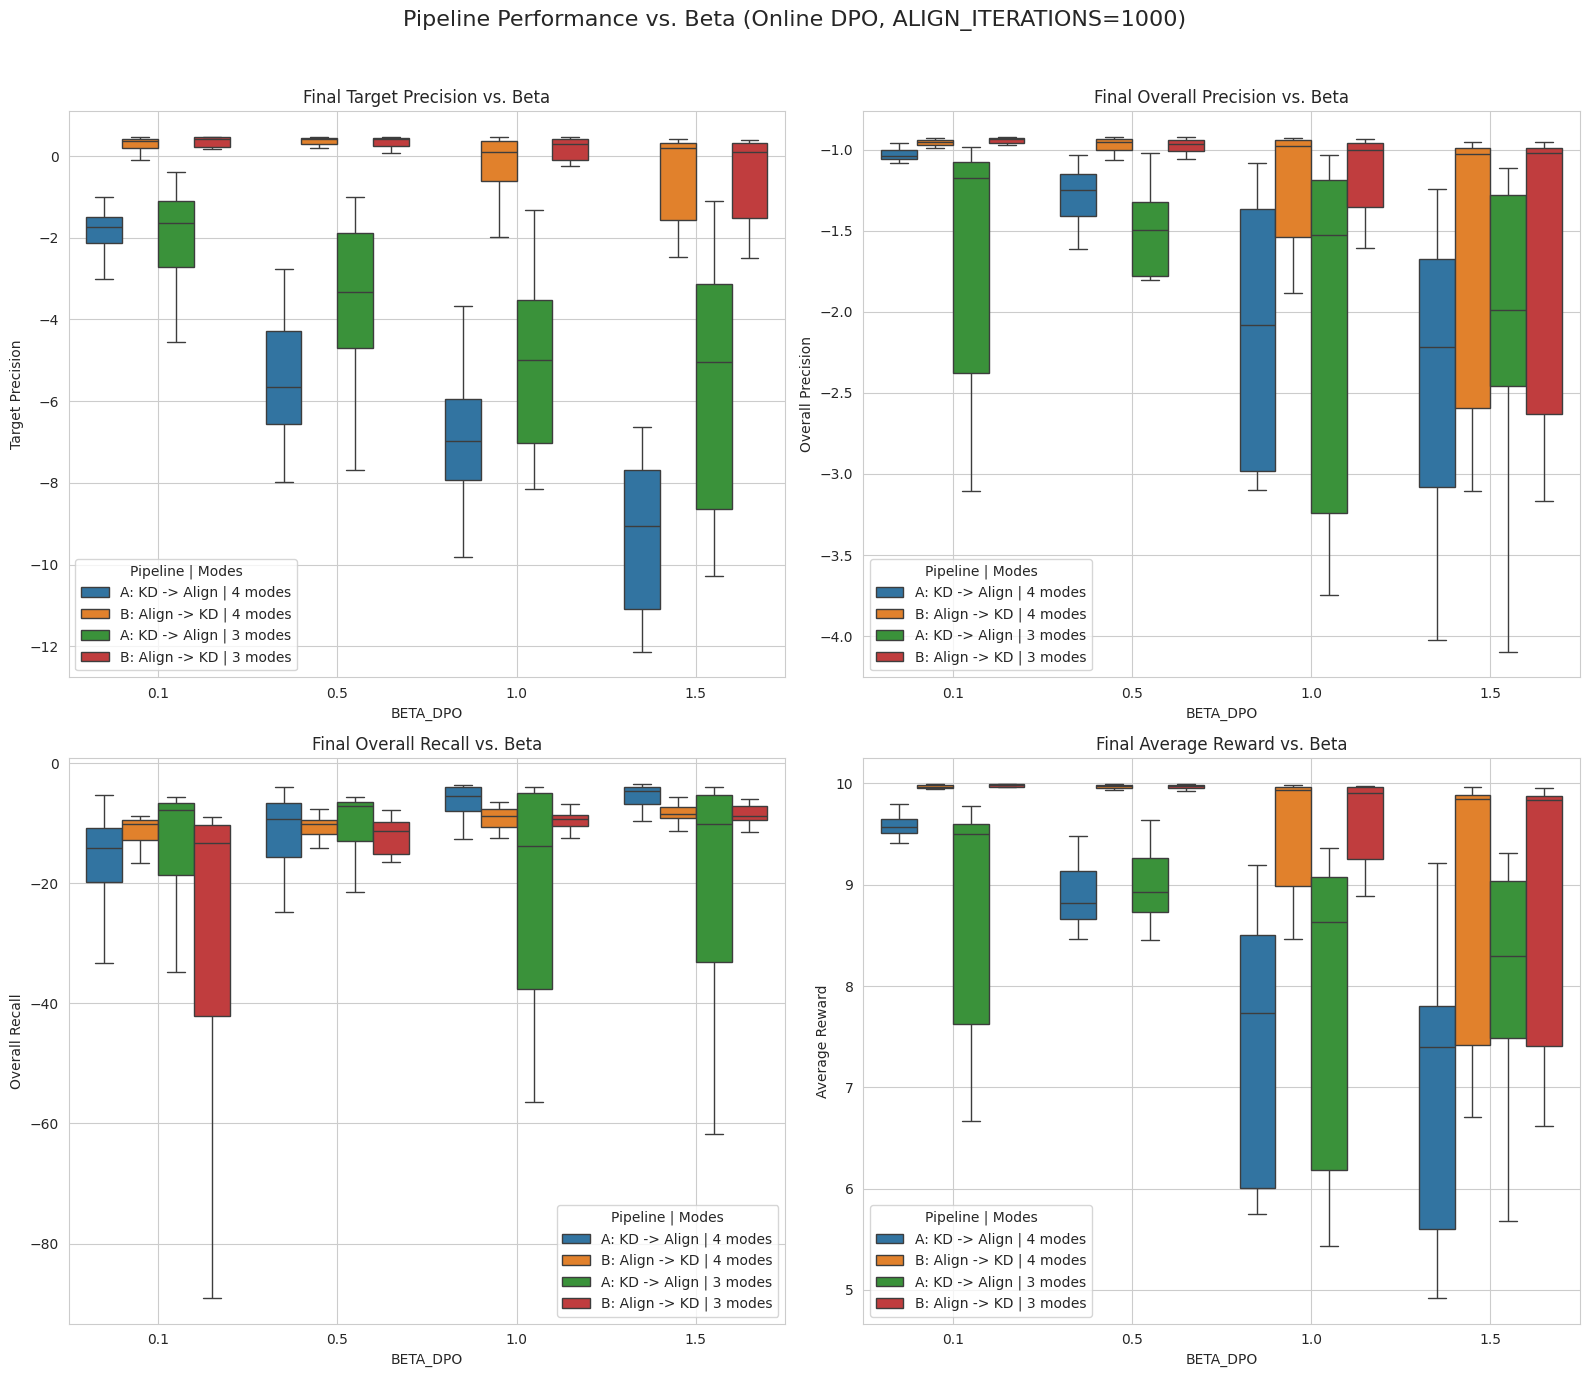

In [1]:
import time
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.distributions as D
from torch.utils.data import TensorDataset, DataLoader

# --- 1. Experiment Environment Setup ---
sns.set_style("whitegrid")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device used: {device}")

# Hyperparameters
N_SAMPLES = 5000
BATCH_SIZE = 256
LEARNING_RATE = 1e-2
N_ITERATIONS_SFT_KD = 2000
N_ITERATIONS_ALIGN = 1000  # Alignment iterations fixed
N_TRIALS_PER_SETTING = 20
KD_SAMPLING_BETA = 1.25

N_SAMPLES_KD = 2000 # Number of samples for Knowledge Distillation (KD)

# --- Experiment Variable Configuration ---
BETA_DPO_arr = [0.1, 0.5, 1.0, 1.5]  # Varying Beta values for DPO

# Mode configuration
N_GT_MODES = 8
N_SFT_MODES = 6
N_FINAL_MODES_arr = [4, 3] # Comparing different final mode counts

# --- Target Mode Configuration ---
# Changed from single target (7) to multiple targets (6, 7)
TARGET_INDICES = [6, 7]

# --- 2. Model and Utility Functions ---
true_centers = np.array([[-1.5, 1.5], [0, 1.5], [1.5, 1.5], [-1.5, 0], [1.5, 0], [-1.5, -1.5], [0, -1.5], [1.5, -1.5]], dtype=np.float32)
true_centers_tensor = torch.from_numpy(true_centers).to(device)
true_cov = torch.eye(2, device=device) * 0.05
mix = D.Categorical(torch.ones(8, device=device)); comp = D.Independent(D.Normal(true_centers_tensor, true_cov.diag().sqrt()), 1)
ground_truth_dist = D.MixtureSameFamily(mix, comp)
gt_validation_set = ground_truth_dist.sample((N_SAMPLES,)).to(device)

# --- Multi-Target Distribution Setup ---
TARGET_CENTERS = true_centers_tensor[TARGET_INDICES] # Shape: (2, 2)

# Validation target distribution: Mixture of modes 6 and 7
target_mix = D.Categorical(torch.ones(len(TARGET_INDICES), device=device))
target_comp = D.Independent(D.Normal(TARGET_CENTERS, true_cov.diag().sqrt()), 1)
main_target_mode_dist = D.MixtureSameFamily(target_mix, target_comp)


class MoGModel(nn.Module):
    def __init__(self, n_components):
        super().__init__(); self.n_components = n_components
        self.mix_logits = nn.Parameter(torch.randn(n_components)); self.mus = nn.Parameter(torch.randn(n_components, 2)); self.log_diags = nn.Parameter(torch.randn(n_components, 2))
    def get_distribution(self):
        mix = D.Categorical(logits=self.mix_logits); comp = D.Independent(D.Normal(self.mus, self.log_diags.exp()), 1)
        return D.MixtureSameFamily(mix, comp)
    def log_prob(self, x): return self.get_distribution().log_prob(x)

@torch.no_grad()
def calculate_precision_recall(model_dist, gt_dist, gt_validation_set):
    model_samples = model_dist.sample((gt_validation_set.shape[0],)); precision = gt_dist.log_prob(model_samples).mean().item()
    recall = model_dist.log_prob(gt_validation_set).mean().item()
    return precision, recall

@torch.no_grad()
def calculate_target_precision(model_dist, target_dist, n_samples=2000):
    model_samples = model_dist.sample((n_samples,)); return target_dist.log_prob(model_samples).mean().item()

# --- Reward Function for Multiple Targets ---
def get_perfect_reward_signal(batch, target_centers):
    """
    batch: (Batch_Size, 2)
    target_centers: (N_Targets, 2) -> here (2, 2)
    """
    # Broadcasting: (Batch, 1, 2) - (N_Targets, 2) -> (Batch, N_Targets, 2)
    diff = batch.unsqueeze(1) - target_centers 
    
    # Calculate squared distances to each target -> (Batch, N_Targets)
    distances_sq = torch.sum(diff**2, dim=2) 
    
    # Calculate Gaussian rewards -> (Batch, N_Targets)
    rewards_all = 10.0 * torch.exp(-distances_sq * 2.0)
    
    # Select max reward (closest target) for each sample -> (Batch,)
    return rewards_all.max(dim=1).values


# --- 3. Pipeline Comparison Experiment ---
results = []
start_time = time.time()
print(f"--- Running Online DPO Pipeline Comparison across Betas (ALIGN_ITERATIONS fixed at {N_ITERATIONS_ALIGN}) ---")
print(f"--- Targeting Modes: {TARGET_INDICES} ---")
print(f"--- Using KD Sampling Beta = {KD_SAMPLING_BETA} ---")

for n_modes in N_FINAL_MODES_arr:
    print(f"\n{'#'*80}\n### TESTING WITH N_FINAL_MODES = {n_modes} ###\n{'#'*80}")
    
    # Main loop: Iterating over Beta values
    for beta_val in BETA_DPO_arr:
        print(f"\n{'='*80}\n--- Testing BETA_DPO = {beta_val:.2f} ({N_TRIALS_PER_SETTING} trials) ---\n{'='*80}")
        for trial in range(N_TRIALS_PER_SETTING):
            
            # Train SFT (Supervised Fine-Tuning) model
            sft_data = ground_truth_dist.sample((N_SAMPLES,)).to(device)
            sft_dataloader = DataLoader(TensorDataset(sft_data), batch_size=BATCH_SIZE, shuffle=True)
            sft_model = MoGModel(n_components=N_SFT_MODES).to(device)
            optimizer_sft = torch.optim.Adam(sft_model.parameters(), lr=LEARNING_RATE)
            for i in range(N_ITERATIONS_SFT_KD):
                for (batch,) in sft_dataloader:
                    optimizer_sft.zero_grad(); loss = -sft_model.log_prob(batch).mean(); loss.backward(); optimizer_sft.step()
            sft_dist = sft_model.get_distribution()
        
            # --- Pipeline A: KD -> Align ---
            print(f"  Trial {trial+1}/{N_TRIALS_PER_SETTING} | Pipeline A (KD -> Align)...")
            # A-1: Knowledge Distillation
            kd_model_a = MoGModel(n_components=n_modes).to(device)
            optimizer_kd_a = torch.optim.Adam(kd_model_a.parameters(), lr=LEARNING_RATE)
            with torch.no_grad():
                modified_logits = sft_dist.mixture_distribution.logits * KD_SAMPLING_BETA
                modified_mix = D.Categorical(logits=modified_logits)
                modified_teacher_dist = D.MixtureSameFamily(modified_mix, sft_dist.component_distribution)
                
            for i in range(N_ITERATIONS_SFT_KD):
                with torch.no_grad(): batch = modified_teacher_dist.sample((BATCH_SIZE,))
                with torch.no_grad(): teacher_log_probs = sft_dist.log_prob(batch)
                student_log_probs = kd_model_a.log_prob(batch)
                loss = nn.functional.kl_div(student_log_probs, teacher_log_probs, log_target=True, reduction='batchmean')
                optimizer_kd_a.zero_grad(); loss.backward(); optimizer_kd_a.step()
            kd_dist_a = kd_model_a.get_distribution()
        
            # A-2: Alignment (Online DPO)
            dpo_model_a = MoGModel(n_components=n_modes).to(device); dpo_model_a.load_state_dict(kd_model_a.state_dict())
            optimizer_a = torch.optim.Adam(dpo_model_a.parameters(), lr=LEARNING_RATE/10)
            
            # Fixed alignment iterations
            for i in range(N_ITERATIONS_ALIGN):
                # 1. Generate data pool
                with torch.no_grad(): data_pool_a = dpo_model_a.get_distribution().sample((BATCH_SIZE*5,))
                
                # 2. Generate preference pairs (considering multiple targets)
                indices_a = torch.randperm(len(data_pool_a))
                y_w_list_a, y_l_list_a = [], []
                for k in range(0, len(indices_a) - 1, 2):
                    y1, y2 = data_pool_a[indices_a[k]], data_pool_a[indices_a[k+1]]
                    
                    # Calculate minimum distance to any target
                    # y1(2,) - TARGET_CENTERS(2,2) -> need to unsqueeze y1 -> (1,2)
                    dist1 = torch.sum((y1.unsqueeze(0) - TARGET_CENTERS)**2, dim=1).min()
                    dist2 = torch.sum((y2.unsqueeze(0) - TARGET_CENTERS)**2, dim=1).min()
                    
                    if dist1 < dist2: y_w_list_a.append(y1.unsqueeze(0)); y_l_list_a.append(y2.unsqueeze(0))
                    else: y_w_list_a.append(y2.unsqueeze(0)); y_l_list_a.append(y1.unsqueeze(0))
                if not y_w_list_a: continue
                dpo_dataloader_a = DataLoader(TensorDataset(torch.cat(y_w_list_a), torch.cat(y_l_list_a)), batch_size=BATCH_SIZE)
                
                # 3. Train for one epoch
                for y_w_b, y_l_b in dpo_dataloader_a:
                    optimizer_a.zero_grad()
                    with torch.no_grad(): ref_w, ref_l = kd_dist_a.log_prob(y_w_b), kd_dist_a.log_prob(y_l_b)
                    
                    theta_w, theta_l = dpo_model_a.log_prob(y_w_b), dpo_model_a.log_prob(y_l_b)
                    # Use current beta_val from loop
                    r_hat_w, r_hat_l = beta_val * (theta_w - ref_w), beta_val * (theta_l - ref_l)
                    loss = -torch.nn.functional.logsigmoid(r_hat_w - r_hat_l).mean()
                    loss.backward(); optimizer_a.step()
            
            final_dist_a = dpo_model_a.get_distribution()
            p_a, r_a = calculate_precision_recall(final_dist_a, ground_truth_dist, gt_validation_set)
            tp_a = calculate_target_precision(final_dist_a, main_target_mode_dist)
            
            with torch.no_grad():
                post_rl_samples_a = final_dist_a.sample((N_SAMPLES,))
                # Pass TARGET_CENTERS for reward calculation
                post_rl_avg_reward_a = get_perfect_reward_signal(post_rl_samples_a, TARGET_CENTERS).mean().item()
            
            print(f"    -> Result A: Precision={p_a:.3f}, Recall={r_a:.3f}, Target Precision={tp_a:.3f}, Reward={post_rl_avg_reward_a:.3f}")
            
            # Store results (using beta as key)
            results.append({'pipeline': 'A: KD -> Align', 'n_modes': n_modes, 'beta': beta_val, 'precision': p_a, 'recall': r_a, 'target_precision': tp_a, 'post_rl_reward': post_rl_avg_reward_a})
        
            # --- Pipeline B: Align -> KD ---
            print(f"  Trial {trial+1}/{N_TRIALS_PER_SETTING} | Pipeline B (Align -> KD)...")
            # B-1: Alignment (Online DPO on SFT model)
            dpo_model_b_interim = MoGModel(n_components=N_SFT_MODES).to(device); dpo_model_b_interim.load_state_dict(sft_model.state_dict())
            optimizer_b1 = torch.optim.Adam(dpo_model_b_interim.parameters(), lr=LEARNING_RATE/10)

            # Fixed alignment iterations
            for i in range(N_ITERATIONS_ALIGN):
                # 1. Generate data pool
                with torch.no_grad(): data_pool_b = dpo_model_b_interim.get_distribution().sample((BATCH_SIZE*5,))
                
                # 2. Generate preference pairs (considering multiple targets)
                indices_b = torch.randperm(len(data_pool_b))
                y_w_list_b, y_l_list_b = [], []
                for k in range(0, len(indices_b) - 1, 2):
                    y1, y2 = data_pool_b[indices_b[k]], data_pool_b[indices_b[k+1]]
                    
                    # Calculate minimum distance to any target
                    dist1 = torch.sum((y1.unsqueeze(0) - TARGET_CENTERS)**2, dim=1).min()
                    dist2 = torch.sum((y2.unsqueeze(0) - TARGET_CENTERS)**2, dim=1).min()
                    
                    if dist1 < dist2: y_w_list_b.append(y1.unsqueeze(0)); y_l_list_b.append(y2.unsqueeze(0))
                    else: y_w_list_b.append(y2.unsqueeze(0)); y_l_list_b.append(y1.unsqueeze(0))
                if not y_w_list_b: continue
                dpo_dataloader_b = DataLoader(TensorDataset(torch.cat(y_w_list_b), torch.cat(y_l_list_b)), batch_size=BATCH_SIZE)
                
                # 3. Train for one epoch
                for y_w_b, y_l_b in dpo_dataloader_b:
                    optimizer_b1.zero_grad()
                    with torch.no_grad(): ref_w, ref_l = sft_dist.log_prob(y_w_b), sft_dist.log_prob(y_l_b)
                    
                    theta_w, theta_l = dpo_model_b_interim.log_prob(y_w_b), dpo_model_b_interim.log_prob(y_l_b)
                    # Use current beta_val from loop
                    r_hat_w, r_hat_l = beta_val * (theta_w - ref_w), beta_val * (theta_l - ref_l)
                    loss = -torch.nn.functional.logsigmoid(r_hat_w - r_hat_l).mean()
                    loss.backward(); optimizer_b1.step()
            aligned_dist_b = dpo_model_b_interim.get_distribution()
        
            # B-2: Knowledge Distillation
            final_model_b = MoGModel(n_components=n_modes).to(device)
            optimizer_b2 = torch.optim.Adam(final_model_b.parameters(), lr=LEARNING_RATE)
            with torch.no_grad():
                modified_logits = aligned_dist_b.mixture_distribution.logits * KD_SAMPLING_BETA
                modified_mix = D.Categorical(logits=modified_logits)
                modified_teacher_dist = D.MixtureSameFamily(modified_mix, aligned_dist_b.component_distribution)
                
            for i in range(N_ITERATIONS_SFT_KD):
                with torch.no_grad(): batch = modified_teacher_dist.sample((BATCH_SIZE,))
                with torch.no_grad(): teacher_log_probs = aligned_dist_b.log_prob(batch)
                student_log_probs = final_model_b.log_prob(batch)
                loss = nn.functional.kl_div(student_log_probs, teacher_log_probs, log_target=True, reduction='batchmean')
                optimizer_b2.zero_grad(); loss.backward(); optimizer_b2.step()
            
            final_dist_b = final_model_b.get_distribution()
            p_b, r_b = calculate_precision_recall(final_dist_b, ground_truth_dist, gt_validation_set)
            tp_b = calculate_target_precision(final_dist_b, main_target_mode_dist)

            with torch.no_grad():
                post_rl_samples_b = final_dist_b.sample((N_SAMPLES,))
                # Pass TARGET_CENTERS for reward calculation
                post_rl_avg_reward_b = get_perfect_reward_signal(post_rl_samples_b, TARGET_CENTERS).mean().item()
                
            print(f"    -> Result B: Precision={p_b:.3f}, Recall={r_b:.3f}, Target Precision={tp_b:.3f}, Reward={post_rl_avg_reward_b:.3f}")
                
            # Store results (using beta as key)
            results.append({'pipeline': 'B: Align -> KD', 'n_modes': n_modes, 'beta': beta_val, 'precision': p_b, 'recall': r_b, 'target_precision': tp_b, 'post_rl_reward': post_rl_avg_reward_b})
        
        print(f"Beta={beta_val:.2f} complete.")

end_time = time.time()
print(f"\nTotal experiment time: {end_time - start_time:.2f} seconds")


# --- 4. Results Aggregation and Visualization ---
results_df = pd.DataFrame(results)
results_df['hue'] = results_df['pipeline'] + ' | ' + results_df['n_modes'].astype(str) + ' modes'

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
# Set plot title
fig.suptitle(f"Pipeline Performance vs. Beta (Online DPO, ALIGN_ITERATIONS={N_ITERATIONS_ALIGN})", fontsize=16)

# Plot 1: Target Precision vs. Beta
sns.boxplot(data=results_df, x='beta', y='target_precision', hue='hue', ax=axes[0,0], showfliers=False)
axes[0,0].set_title("Final Target Precision vs. Beta")
axes[0,0].set_xlabel("BETA_DPO"); axes[0,0].set_ylabel("Target Precision"); axes[0,0].grid(True)
axes[0,0].legend(title='Pipeline | Modes')

# Plot 2: Overall Precision vs. Beta
sns.boxplot(data=results_df, x='beta', y='precision', hue='hue', ax=axes[0,1], showfliers=False)
axes[0,1].set_title("Final Overall Precision vs. Beta")
axes[0,1].set_xlabel("BETA_DPO"); axes[0,1].set_ylabel("Overall Precision"); axes[0,1].grid(True)
axes[0,1].legend(title='Pipeline | Modes')

# Plot 3: Overall Recall vs. Beta
sns.boxplot(data=results_df, x='beta', y='recall', hue='hue', ax=axes[1,0], showfliers=False)
axes[1,0].set_title("Final Overall Recall vs. Beta")
axes[1,0].set_xlabel("BETA_DPO"); axes[1,0].set_ylabel("Overall Recall"); axes[1,0].grid(True)
axes[1,0].legend(title='Pipeline | Modes')

# Plot 4: Average Reward vs. Beta
sns.boxplot(data=results_df, x='beta', y='post_rl_reward', hue='hue', ax=axes[1,1], showfliers=False)
axes[1,1].set_title("Final Average Reward vs. Beta")
axes[1,1].set_xlabel("BETA_DPO"); axes[1,1].set_ylabel("Average Reward"); axes[1,1].grid(True)
axes[1,1].legend(title='Pipeline | Modes')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()